# Ejercicio 4 · Mejoras

## Enunciado

> **Ejercicio 4 (1.5 Puntos):**
> El propósito de este ejercicio opcional es que demostréis vuestro conocimiento en la construcción del entorno y/o en los entrenamientos de los modelos de RL.
> Como ideas, podéis continuar con el desarrollo de los ejercicios anteriores:
>
> Mejoras ejercicio 2:
>
> **Idea A)** Modificar el sistema de recompensas del TWAP para mejorar sus resultados (media del VWAP o una menor dispersión). Es este caso será necesario modificar el estado para incorporar información del libro de órdenes y/o de la tendencia del mercado.
> No se piden buenos resultados, ya que para un correcto entrenamiento se pueden necesitar más y mejores datos de entrenamientos, pero sí se pide que el razonamiento y pasos seguidos sean los correctos
>
> **Idea B)** Añadir recompensas para evitar 1. Que el algoritmo deje volumen pendiente y 2. Que el algoritmo consuma aproximadamente un 90% de la duración de la orden para dejar un cierto margen. Es necesario una correcta calibración de las recompensas para asegurarnos la estabilidad de resultados
>
> Mejoras ejercicio 3:
>
> **Idea C)** Establece condiciones de parada del entrenamiento en base al aprendizaje + guarda los pesos del modelo cada cierto tiempo para evitar perder un buen entrenamiento. Incorpora la posibilidad de recuperar dicho entrenamiento
>
> También se ofrece la libertad de incorporar cualquiera de los puntos discutidos durante la clase teórica de creación de entornos y entrenamiento de modelos, pero en ese caso será necesario especificar con detalle cuál ha sido la mejora incorporada y la lógica seguida.

**Hacemos las tres ideas y tres extras.**

## Resumen

| | Qué conseguimos |
|---|---|
| **Idea B** | El agente compra el 100 % de la orden y termina hacia el **89 % del tiempo**, igual en 5 repeticiones y en test |
| **Idea C** | El entrenamiento **para solo** al cumplir el objetivo (100-150 episodios en vez de 300) con el mismo resultado; se puede **cortar y seguir** exactamente igual |
| **Idea A** | Mirando el mercado, ahorra **+0,15 pb** por orden frente al TWAP; con datos desordenados (placebo) no ahorra nada. Una regla simple ahorra más, pero es mucho más irregular |
| Extra · pasillo | El agente puede elegir cuándo acabar dentro del 80-95 %, pero es menos estable que el plan fijo |
| Extra · robustez | No falla con órdenes que nunca vio ni empezando tarde |

**Cómo leerlo.** Los entrenamientos ya están hechos con los scripts de `common/scripts/` y guardados en `results/`.
Este notebook solo lee esos resultados y dibuja las figuras. El código nuevo está en `notebooks/common/ej4.py`.

Palabras que usamos:
- **Orden:** comprar *n* títulos en *N* pasos de 5 segundos.
- **Plan TWAP:** comprar al mismo ritmo todo el rato.
- **Error frente al plan:** cuántos títulos se separa el agente del plan, como máximo. Menos es mejor.
- **pb:** punto básico, 0,01 % del precio.
- **Semilla:** una repetición del entrenamiento con otro azar. Si varias semillas dan lo mismo, el resultado es fiable.

In [1]:
import sys, json
from pathlib import Path
from IPython.display import display, Markdown
ROOT = Path.cwd() if (Path.cwd() / "notebooks" / "common").is_dir() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "notebooks"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from common import data as dt, protocol as pr, plots as pl, ej4
from common.env import BestExecutionEnv
torch.set_num_threads(1)
pd.set_option("display.precision", 2)
%matplotlib inline

DATA = dt.load("REP")
train, val, test = DATA["train"], DATA["val"], DATA["test"]
GRID = pr.make_grid(train, n_days=3, seed=0)     # 27 órdenes fijas para comparar siempre igual

def tabla(df, by):
    # Resumen sencillo por grupo
    g = df.groupby(by)
    out = pd.DataFrame({
        "órdenes completas (%)": g.completed.mean() * 100,
        "dentro de la banda 80-95 % (%)": g.in_band.mean() * 100,
        "acaba en (% del tiempo)": g.t_fin.mean() * 100,
        "error frente al plan (títulos)": g.max_err_h.mean(),
    })
    return out.round(1)

## 1. Idea B · Acabar hacia el 90 % del tiempo sin dejar nada pendiente

**Qué hacemos.** En el ej. 2 el agente copiaba un TWAP que usa el 100 % del tiempo. Ahora le damos un plan
que **termina al 90 %**. La recompensa castiga separarse de ese plan en cada paso. Además, al final, resta
**k × (títulos pendientes / n)**.

Aceptamos terminar entre el **80 % y el 95 %** del tiempo, que es el rango que se dio en clase, siempre
con el 100 % comprado.

**Calibrar antes de entrenar.** Medimos cuánto pesa cada parte de la recompensa con políticas fijas.

In [2]:
CAL = ej4.calibration(train, GRID, gammas=(0.9,), ks=(1.0, 10.0, 50.0)).xs(0.9, level="gamma")
CAL = CAL[["seguimiento", "pendiente_frac", "t_fin", "terminal_k1", "terminal_k10", "terminal_k50"]]
CAL.columns = ["castigo por separarse del plan", "fracción pendiente", "acaba en", "castigo final k=1", "k=10", "k=50"]
CAL.round(2)

,castigo por separarse del plan,fracción pendiente,acaba en,castigo final k=1,k=10,k=50
política,,,,,,
TWAP 0.9·N (objetivo),-9.55,0.00,0.88,0.00,0.00,0.00
TWAP 1·N (ej. 2),-54.51,0.00,0.98,0.00,0.00,0.00
TWAP 0.9·N que deja el último 5 %,-15.76,0.04,1.00,-0.04,-0.41,-2.07
"TWAP 0,8·N (acaba pronto)",-65.49,0.00,0.79,0.00,0.00,0.00
todo al principio,-48.13,0.00,0.10,0.00,0.00,0.00


**Lectura.** Dejar sin comprar el último 5 % ya cuesta **6,2** por separarse del plan, y el castigo final con
k = 1 solo añade **0,04**. Es decir, el plan al 90 % ya obliga a terminar por sí mismo, y k es solo un seguro.

**Prueba.** Entrenamos 7 versiones, cambiando una cosa cada vez, con 3 repeticiones de 300 episodios cada una:
- el plan al 100 % del ej. 2, como referencia;
- el plan al 90 % con k = 0, 1, 10 y 50;
- un γ más alto (0,995), que es lo que recomienda la teoría cuando hay un castigo al final.

In [3]:
B = pr.load_df("ej4_ideaB")
B["config"] = [("plan al 100 % (ej. 2)" if h == 1 else f"plan al 90 % · k={k:g} · γ={g:g}") for h, k, g in zip(B.horizon, B.k, B.gamma)]
tabla(B, "config")

,órdenes completas (%),dentro de la banda 80-95 % (%),acaba en (% del tiempo),error frente al plan (títulos)
config,,,,
plan al 100 % (ej. 2),100.0,0.0,98.8,0.9
plan al 90 % · k=0 · γ=0.9,100.0,100.0,88.7,0.9
plan al 90 % · k=0 · γ=0.995,100.0,100.0,86.4,2.6
plan al 90 % · k=1 · γ=0.9,100.0,100.0,88.7,0.9
plan al 90 % · k=10 · γ=0.9,100.0,100.0,88.8,0.9
plan al 90 % · k=10 · γ=0.995,33.3,33.3,95.9,3.3
plan al 90 % · k=50 · γ=0.9,100.0,100.0,88.8,0.9


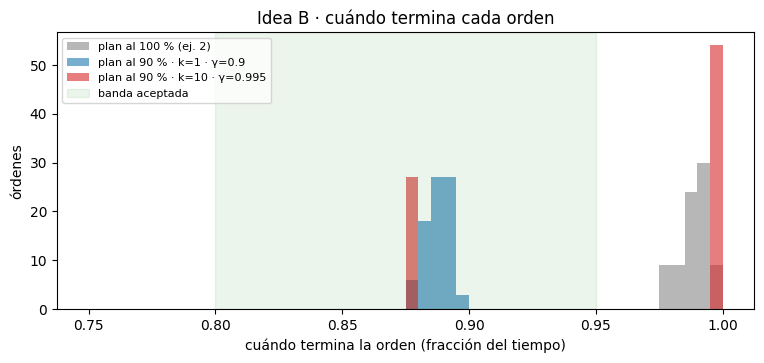

In [4]:
fig, ax = plt.subplots(figsize=(9, 3.6))
bins = np.linspace(0.75, 1.0, 51)
for cfg, col in [("plan al 100 % (ej. 2)", "#888888"), ("plan al 90 % · k=1 · γ=0.9", "#1f77b4"),
                 ("plan al 90 % · k=10 · γ=0.995", "#d62728")]:
    ax.hist(B[B.config == cfg].t_fin, bins=bins, alpha=0.6, color=col, label=cfg)
ax.axvspan(0.8, 0.95, color="green", alpha=0.08, label="banda aceptada")
ax.set_xlabel("cuándo termina la orden (fracción del tiempo)"); ax.set_ylabel("órdenes"); ax.legend(fontsize=8)
ax.set_title("Idea B · cuándo termina cada orden"); pl.save(fig, "ej4_ideaB_tfin")

**Lectura.**
- **Con el plan al 90 %** todas las órdenes se completan y todas acaban dentro de la banda, hacia el 88,7 %
  del tiempo, con el mismo error que un TWAP perfecto. Da igual el valor de k.
- **El γ alto lo empeora.** El agente se vuelve irregular y, con k = 10, deja órdenes a medias (las barras
  rojas en 1,0). Aquí el castigo llega en cada paso, no solo al final, así que no hace falta mirar tan lejos.
- **Elegimos plan al 90 %, k = 1 y γ = 0,9.** Con 5 repeticiones y en test, que miramos una sola vez, sale
  lo mismo.

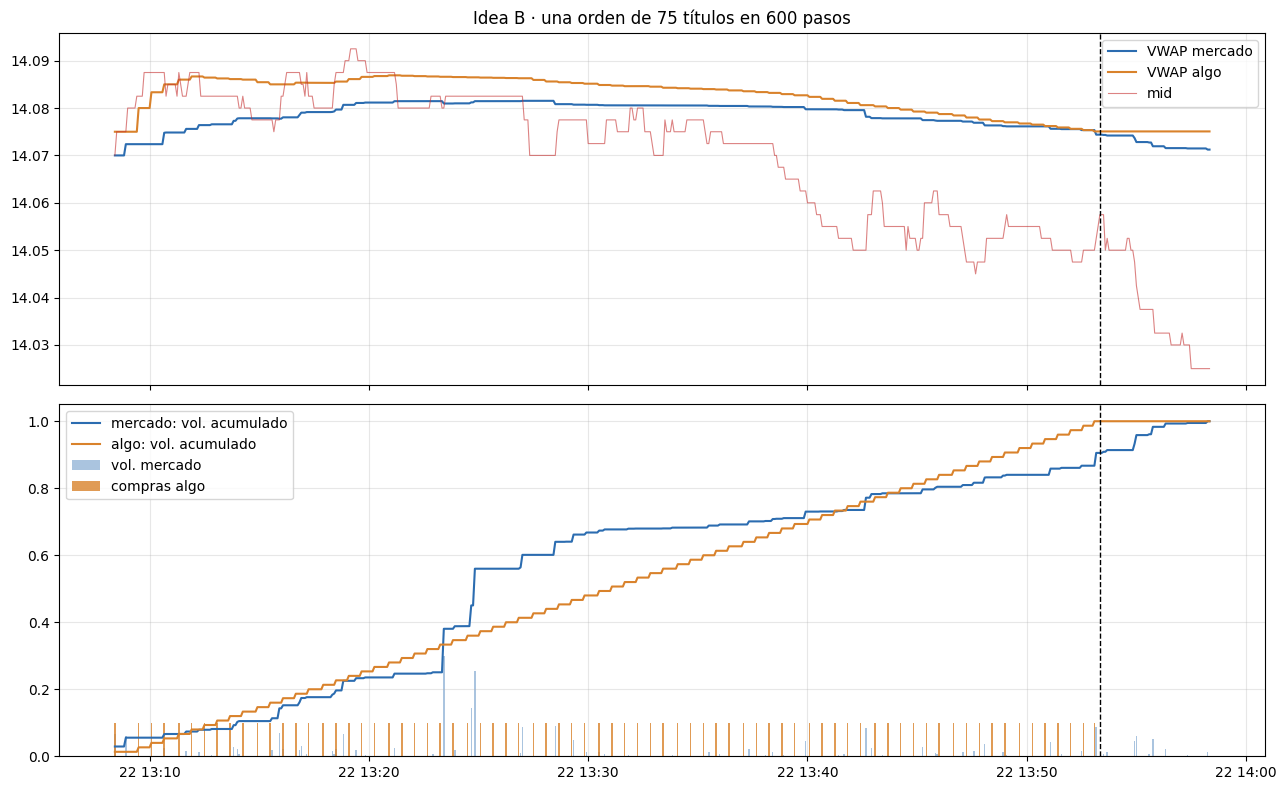

In [5]:
# Una orden de ejemplo: la línea naranja de abajo (lo comprado) llega a 1 hacia el 90 % del tiempo
agent_b = ej4.load_agent_b(0, train)
cfg = max(GRID, key=lambda c: (c["n_bins"], c["vol_care"]))
env = BestExecutionEnv(train, reward=ej4.make_reward(0.9, 1.0), seed=0)
agent_b.env = env; agent_b.set_trainable(False)
pr.run_episode(env, agent_b, cfg)
fig = pl.plot_results(env, title=f"Idea B · una orden de {env.vol_care} títulos en {env.episode_bins} pasos")
mkt = env.stats_df()[1]
for a in fig.axes:
    a.axvline(mkt.index[int(0.9 * len(mkt)) - 1], color="k", ls="--", lw=1)
pl.save(fig, "ej4_ideaB_episodio")

In [6]:
B5 = pr.load_df("ej4_ideaB_5semillas")
BT = pr.load_df("ej4_ideaB_test")
display(Markdown("**5 semillas (train)**")); display(tabla(B5, "seed"))
display(Markdown("**Test, mirado una sola vez (3 semillas y el TWAP al 90 %)**")); display(tabla(BT, ["policy", "seed"]))

**5 semillas (train)**

,órdenes completas (%),dentro de la banda 80-95 % (%),acaba en (% del tiempo),error frente al plan (títulos)
seed,,,,
0,100.0,100.0,88.9,0.9
1,100.0,100.0,88.7,0.9
2,100.0,100.0,88.4,0.9
3,100.0,100.0,88.6,0.9
4,100.0,100.0,88.9,0.9


**Test, mirado una sola vez (3 semillas y el TWAP al 90 %)**

órdenes completas (%)  dentro de la banda 80-95 % (%)  \
policy    seed                                                          
DDQN       0                    100.0                           100.0   
           1                    100.0                           100.0   
           2                    100.0                           100.0   
TWAP 0.9N -1                    100.0                           100.0   

                acaba en (% del tiempo)  error frente al plan (títulos)  
policy    seed                                                           
DDQN       0                       88.9                             0.9  
           1                       88.7                             0.9  
           2                       88.4                             0.9  
TWAP 0.9N -1                       88.3                             0.9

## 2. Extra · Una banda en vez de un plan fijo

**Qué hacemos.** El plan al 90 % obliga a terminar casi siempre en el mismo punto. Probamos otra forma más
fiel a lo que se dijo en clase: un **pasillo** entre «acabar al 80 %» y «acabar al 95 %». Dentro del pasillo
no hay castigo, y fuera se castiga la distancia. Así el agente elige cuándo terminar.

,órdenes completas (%),dentro de la banda 80-95 % (%),acaba en (% del tiempo),error frente al plan (títulos)
plan al 90 %,100.0,100.0,88.7,0.9
pasillo 80-95 %,100.0,88.9,87.9,2.8


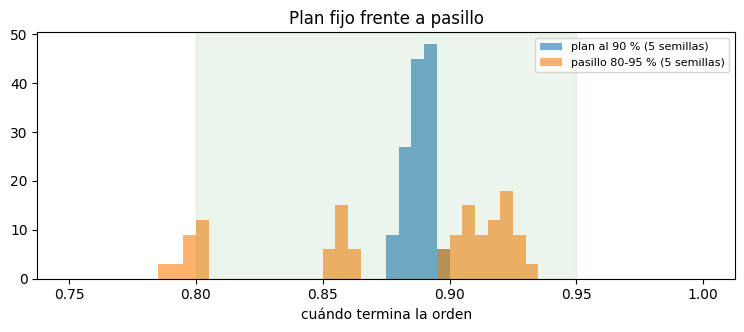

In [7]:
BAND = pr.load_df("ej4_banda")
comp = pd.concat([tabla(B5, "seed").mean().rename("plan al 90 %"), tabla(BAND, "seed").mean().rename("pasillo 80-95 %")], axis=1).T
display(comp.round(1))
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.hist(B5.t_fin, bins=bins, alpha=0.6, color="#1f77b4", label="plan al 90 % (5 semillas)")
ax.hist(BAND.t_fin, bins=bins, alpha=0.6, color="#ff7f0e", label="pasillo 80-95 % (5 semillas)")
ax.axvspan(0.8, 0.95, color="green", alpha=0.08)
ax.set_xlabel("cuándo termina la orden"); ax.legend(fontsize=8); ax.set_title("Plan fijo frente a pasillo")
pl.save(fig, "ej4_banda")

**Lectura.**
- **Con el pasillo, el agente elige.** Cada repetición acaba en un punto distinto: 86 %, 80 %, 92 %, 92 % y 90 %.
- **Pero es menos estable.** Una repetición se queda justo por debajo del 80 % en la mitad de las órdenes, y el
  error frente al plan sube de 0,9 a 1,7-5,6 títulos.
- **Nos quedamos con el plan fijo**, que acaba siempre dentro de la banda. El pasillo sirve si se quiere dar
  libertad al agente, por ejemplo junto con la idea A.

## 3. Extra · ¿Aguanta situaciones que no vio al entrenar?

Usamos el agente de la idea B (5 semillas) y lo ponemos en dos situaciones nuevas:
- **Órdenes fuera de rango.** Entrenó con órdenes de 400-600 pasos y del 7,5-12,5 % del volumen. Aquí le damos
  órdenes de 250-800 pasos y del 4-20 %.
- **Empezar con retraso.** Durante el 20 %, 40 % o 60 % inicial del tiempo no le dejamos comprar. ¿Se
  recupera y termina a tiempo?

In [8]:
ROB = pr.load_df("ej4_robustez")
ROB["quién"] = np.where(ROB.seed < 0, "TWAP al 90 %", "agente (5 semillas)")
tabla(ROB, ["prueba", "quién"])

órdenes completas (%)  \
prueba         quién                                        
fuera de rango TWAP al 90 %                         100.0   
               agente (5 semillas)                  100.0   
retraso 20%    TWAP al 90 %                         100.0   
               agente (5 semillas)                  100.0   
retraso 40%    TWAP al 90 %                         100.0   
               agente (5 semillas)                  100.0   
retraso 60%    TWAP al 90 %                         100.0   
               agente (5 semillas)                  100.0   

                                    dentro de la banda 80-95 % (%)  \
prueba         quién                                                 
fuera de rango TWAP al 90 %                                  100.0   
               agente (5 semillas)                           100.0   
retraso 20%    TWAP al 90 %                                  100.0   
               agente (5 semillas)                           100.0   
retraso 40%    TWAP al 90 %                                  100.0   
               agente (5 semillas)                           100.0   
retraso 60%    TWAP al 90 %                                  100.0   
               agente (5 semillas)                           100.0   

                                    acaba en (% del tiempo)  \
prueba         quién                                          
fuera de rango TWAP al 90 %                            87.1   
               agente (5 semillas)                     87.6   
retraso 20%    TWAP al 90 %                            88.3   
               agente (5 semillas)                     88.7   
retraso 40%    TWAP al 90 %                            88.3   
               agente (5 semillas)                     88.7   
retraso 60%    TWAP al 90 %                            88.3   
               agente (5 semillas)                     88.7   

                                    error frente al plan (títulos)  
prueba         quién                                                
fuera de rango TWAP al 90 %                                    0.9  
               agente (5 semillas)                             1.0  
retraso 20%    TWAP al 90 %                                   11.1  
               agente (5 semillas)                            11.1  
retraso 40%    TWAP al 90 %                                   22.2  
               agente (5 semillas)                            22.2  
retraso 60%    TWAP al 90 %                                   33.3  
               agente (5 semillas)                            33.3

**Lectura.**
- **Órdenes nunca vistas:** completa el 100 % y acaba dentro de la banda. Su error es de 0,9-1,0 títulos,
  frente a 0,88 del TWAP perfecto. Aprendió la regla, no se memorizó los tamaños.
- **Empezar con retraso:** compra más deprisa hasta alcanzar el plan y termina igual que el TWAP, incluso
  perdiendo el 60 % del tiempo. El error alto en esas filas es el propio retraso, que nadie puede evitar
  (el TWAP tiene el mismo).

## 4. Idea C · Parar a tiempo, guardar y recuperar

**Qué hacemos.** Cada 25 episodios examinamos al agente con las 27 órdenes fijas, sin explorar, y miramos
su error frente al plan. Después de cada examen:
- **Guardamos** el último modelo y, si es el mejor hasta ahora, también una copia como «el mejor».
- **Paramos** si se cumple alguna de estas condiciones:
  1. el error baja de 1,5 títulos dos exámenes seguidos (objetivo cumplido);
  2. lleva 6 exámenes sin mejorar (estancado);
  3. llega a 600 episodios (tope).

Lo que guardamos es **todo**: la red, el optimizador, la memoria de experiencias, el azar y los contadores.
Por eso se puede seguir exactamente donde se dejó.

Usamos la recompensa de la idea B y la exploración del ej. 3.

,episodios hasta parar,por qué paró
seed,,
0,125,objetivo: 2 evaluaciones seguidas con error ≤ 1.5
1,125,objetivo: 2 evaluaciones seguidas con error ≤ 1.5
2,150,objetivo: 2 evaluaciones seguidas con error ≤ 1.5
3,150,objetivo: 2 evaluaciones seguidas con error ≤ 1.5
4,100,objetivo: 2 evaluaciones seguidas con error ≤ 1.5


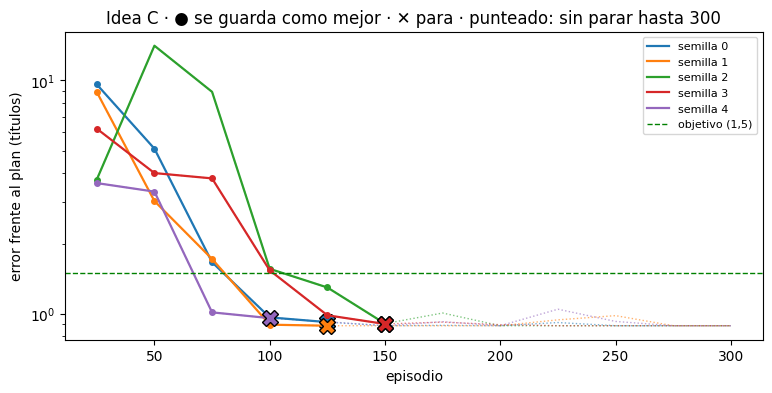

In [9]:
C_SUM = json.loads((pr.RESULTS / "ej4_ideaC.json").read_text(encoding="utf-8"))
C_EV, C_FX = pr.load_df("ej4_ideaC_evals"), pr.load_df("ej4_ideaC_evals_fijo")
display(pd.DataFrame(C_SUM["runs"]).set_index("seed")[["episodes", "stop"]].rename(
    columns={"episodes": "episodios hasta parar", "stop": "por qué paró"}))
fig, ax = plt.subplots(figsize=(9, 4))
cols = plt.cm.tab10.colors
for s, g in C_FX.groupby("seed"):
    ax.plot(g.episode, g.max_err_h, ":", color=cols[s], lw=1, alpha=0.6)
for s, g in C_EV.groupby("seed"):
    ax.plot(g.episode, g.max_err_h, "-", color=cols[s], lw=1.6, label=f"semilla {s}")
    ax.plot(g[g.saved_best].episode, g[g.saved_best].max_err_h, "o", color=cols[s], ms=4)
    ax.plot(g.episode.iloc[-1], g.max_err_h.iloc[-1], "X", color=cols[s], ms=11, mec="k")
ax.axhline(C_SUM["target"], color="green", ls="--", lw=1, label="objetivo (1,5)")
ax.set_yscale("log"); ax.set_xlabel("episodio"); ax.set_ylabel("error frente al plan (títulos)")
ax.set_title("Idea C · ● se guarda como mejor · ✕ para · punteado: sin parar hasta 300"); ax.legend(fontsize=8)
pl.save(fig, "ej4_ideaC_training")

In [10]:
C_FIN = pr.load_df("ej4_ideaC_final")
t = C_FIN.groupby(["checkpoint"]).agg(error=("max_err_h", "mean"), completas=("completed", "mean"))
t.index = t.index.map({"best": "con parada · mejor", "last": "con parada · último",
                       "sin parada · best": "sin parada (300) · mejor", "sin parada · last": "sin parada (300) · último"})
display(t.round(3))
display(Markdown(f"**Prueba de recuperación:** se corta en el episodio {C_SUM['demo']['cut_episode']}, se carga lo guardado en el "
                 f"{C_SUM['demo']['checkpoint_episode']} con un agente nuevo y se sigue. ¿Sale exactamente igual que sin cortar? "
                 f"Curvas: **{'sí' if C_SUM['demo']['curves_equal'] else 'no'}** · pesos de la red: **{'sí' if C_SUM['demo']['weights_equal'] else 'no'}**."))

,error,completas
checkpoint,,
con parada · mejor,0.92,1.0
con parada · último,0.92,1.0
sin parada (300) · mejor,0.89,1.0
sin parada (300) · último,0.89,1.0


**Prueba de recuperación:** se corta en el episodio 60, se carga lo guardado en el 50 con un agente nuevo y se sigue. ¿Sale exactamente igual que sin cortar? Curvas: **sí** · pesos de la red: **sí**.

**Lectura.**
- **Para antes sin perder calidad.** Las 5 repeticiones paran solas al cumplir el objetivo, de media en el
  episodio 130, en lugar de 300. El error final es de 0,89-0,96 títulos, frente a 0,89 entrenando los 300.
- **La copia del mejor protege.** En la repetición 2 el agente «olvida» lo aprendido entre los episodios 25 y 75:
  en el 75 no completa ninguna orden. Mientras tanto, la copia del mejor seguía guardando el modelo bueno.
- **Recuperar funciona.** Al cortar y seguir sale exactamente lo mismo que sin cortar. Lo comprueban también los
  tests de `common/test_ej4.py`.

## 5. Idea A · Pagar mejor precio mirando el mercado

**Qué hacemos.**
1. **Estado.** Además de tiempo y volumen restantes, el agente ve 4 datos del mercado en ese momento:
   - **spread**: diferencia entre el precio de compra y el de venta, es decir, lo caro que es comprar ahora;
   - **desbalanceo**: si hay más compradores o más vendedores esperando;
   - **tendencia** del último minuto;
   - **actividad** del último minuto.

   Todos se calculan solo con lo que ya ha pasado.
2. **Recompensa.** La de la idea B más un pequeño premio por comprar barato en ese momento: (precio medio −
   precio pagado), con un peso *w*. Así no se aparta mucho del plan.
3. **Controles.**
   - **Placebo:** el mismo agente, pero con los datos de mercado desordenados. Si mejora igual, la mejora no
     viene del mercado.
   - **Regla simple de bróker:** «si el spread está en el mínimo, adelanta una compra».
   - **Elección y test:** elegimos *w* con días de validación (270 órdenes) y miramos test una sola vez.

**Ahorro** = cuánto más barato compra que el TWAP al 90 % en la misma orden, en pb. Más es mejor.

In [11]:
A_VAL = pr.load_df("ej4_ideaA_val"); A_INFO = json.loads((pr.RESULTS / "ej4_ideaA.json").read_text(encoding="utf-8"))
A_VAL["agente"] = [f"{'placebo' if p else 'mercado'} · w={w:g}" for w, p in zip(A_VAL.w, A_VAL.placebo)]
g = A_VAL.groupby("agente")
display(pd.DataFrame({"órdenes completas (%)": g.completed.mean() * 100, "dentro de la banda (%)": g.in_band.mean() * 100,
                      "ahorro medio (pb)": g.slip_vs_ref_bps.mean(), "dispersión del ahorro (pb)": g.slip_vs_ref_bps.std(),
                      "error frente al plan": g.max_err_h.mean()}).round(2))
print("w elegido en validación:", A_INFO["w_elegido"])

,órdenes completas (%),dentro de la banda (%),ahorro medio (pb),dispersión del ahorro (pb),error frente al plan
agente,,,,,
mercado · w=0,100.0,100.0,0.00,0.47,1.14
mercado · w=0.01,100.0,100.0,0.04,0.43,0.90
mercado · w=0.03,100.0,100.0,0.26,0.52,1.11
placebo · w=0.01,100.0,100.0,0.02,0.45,0.90
placebo · w=0.03,100.0,100.0,0.01,0.46,0.91


w elegido en validación: 0.03


,órdenes completas (%),dentro de la banda (%),ahorro medio (pb),± error de la media,dispersión (pb)
politica,,,,,
DDQN mercado,100.0,100.0,0.15,0.01,0.40
DDQN placebo,100.0,100.0,-0.02,0.01,0.34
"TWAP 0,9·N",100.0,100.0,0.00,0.00,0.00
regla spread,100.0,100.0,0.34,0.07,1.11


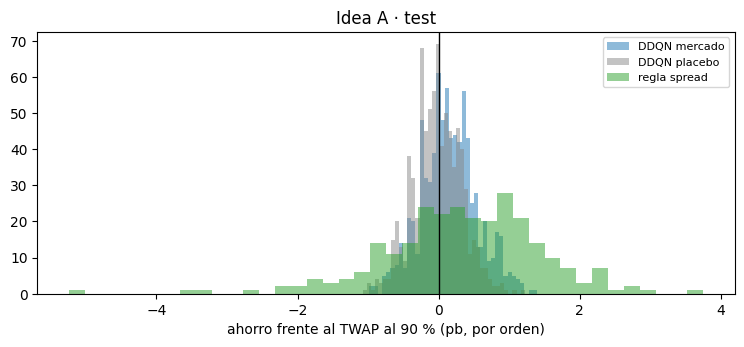

In [12]:
A_TEST = pr.load_df("ej4_ideaA_test")
g = A_TEST.groupby("politica")
TA = pd.DataFrame({"órdenes completas (%)": g.completed.mean() * 100, "dentro de la banda (%)": g.in_band.mean() * 100,
                   "ahorro medio (pb)": g.slip_vs_ref_bps.mean(),
                   "± error de la media": g.slip_vs_ref_bps.std() / np.sqrt(g.size()),
                   "dispersión (pb)": g.slip_vs_ref_bps.std()}).round(2)
display(TA)
fig, ax = plt.subplots(figsize=(9, 3.4))
for pol, col in [("DDQN mercado", "#1f77b4"), ("DDQN placebo", "#888888"), ("regla spread", "#2ca02c")]:
    ax.hist(A_TEST[A_TEST.politica == pol].slip_vs_ref_bps, bins=40, alpha=0.5, color=col, label=pol)
ax.axvline(0, color="k", lw=1); ax.set_xlabel("ahorro frente al TWAP al 90 % (pb, por orden)"); ax.legend(fontsize=8)
ax.set_title("Idea A · test"); pl.save(fig, "ej4_ideaA_test")

**Lectura.**
- **Elección en validación.** w = 0,03 es el que más ahorra (+0,26 pb) cumpliendo todo, así que es el elegido.
- **En test**, el agente que mira el mercado ahorra **+0,15 pb** de media, con un error de ±0,01. Con los datos
  desordenados (placebo) no ahorra nada (−0,02). La mejora viene de mirar el mercado: el agente adelanta
  compras cuando comprar es barato, sin salirse del plan.
- **Es poco, y la regla simple gana en media** (+0,34 pb), pero con casi el triple de dispersión (1,11 frente
  a 0,40 pb). Al cliente le importa también que el resultado sea regular.
- **Para ganar a la regla** harían falta más datos y más entrenamiento, como avisa el propio enunciado. Aquí
  solo hay 300 episodios y 3 repeticiones.

## Conclusión

- **B.** Basta con dar al agente un plan que termine al 90 %. El castigo final por dejar títulos pendientes es un
  seguro que casi no actúa, y subir γ lo empeora. Resultado estable en 5 repeticiones y en test.
- **C.** Parar cuando el agente ya cumple ahorra más de la mitad del entrenamiento. Guardar todo el estado permite
  cortar y seguir sin notar la diferencia, y la copia del mejor protege de los olvidos.
- **A.** Mirar el mercado da una mejora pequeña pero real: el placebo no la consigue. No gana a una regla simple
  en media, pero sí en regularidad.
- **Extras.** El pasillo da libertad a costa de estabilidad. El agente generaliza a órdenes nuevas y se recupera
  si empieza tarde.

**Límites.** Las cifras de B y C usan 27 órdenes fijas, y las de A, 270 de validación y 270 de test. El
simulador no mueve el precio cuando compramos.